# Figure 6 companion · Source-only spatial structure

Strict-source repeat of the whole-cutout Fourier comparison. All methods and JWST
use the same fixed 2σ JWST source mask (all detected neighbours included), with
weights **exactly zero outside sources**. A 3-pixel inward cosine taper and an
outer Tukey window reduce boundary discontinuities. Each image has its own
source-weighted mean subtracted before the transform. The same 1,363 complete
validation cutouts are retained. No model-dependent sample selection is used.

Power ratios are geometric means; signed correlations are arithmetic means.
Bands use 2,000 paired spatial-block bootstrap draws. Widths of 1 and 5 pixels
check mask-edge sensitivity. The original whole-cutout curve is recomputed from
the same cache as a control. Noise within source regions and Fourier mixing from
the shared irregular window remain; this is not a noiseless morphology metric.
The third panel compares source-window reference power to the outside-source
background proxy; its windows differ, so it is not calibrated signal-to-noise.

Local only: no new inference, W&B upload, or manuscript change.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
here=Path.cwd()
workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path: sys.path.insert(0,str(workspace))
from figure_utils import ROOT, FIGURES, COLORS, style, read_json, sha, export
%matplotlib inline
style()
VERSION='v01'
path=FIGURES/'inputs'/f'spatial_spectra_source_{VERSION}.json'
result=read_json(path)
assert result['complete'] and result['local_only'] and result['split']=='validation'
assert sha(ROOT/result['arrays_path'])==result['arrays_sha256']
names=result['methods']
labels={'bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
        'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors={**COLORS,'diffusion_mean3':'#B485B8'}
nrings=len(result['radial_edges_cycles_per_pixel'])-1
frequency=np.array(result['frequencies_cycles_per_pixel'][:nrings])
# Measured target-grid pixel scale ranges 0.0593416–0.0593454 arcsec;
# use the sample median solely for axis conversion, not image resampling.
pixel_scale=.05934367
scale=pixel_scale/frequency
native_nyquist_scale=10*pixel_scale
main=result['summaries']['source3']
print(f"Primary population: {main['objects']:,} / {len(result['object_ids']):,}; complete common-valid coverage.")
print('Background diagnostic population:',len(result['reference_background_ids']))
print('No inference or external uploads.')


Primary population: 1,363 / 2,118; complete common-valid coverage.
Background diagnostic population: 1356
No inference or external uploads.


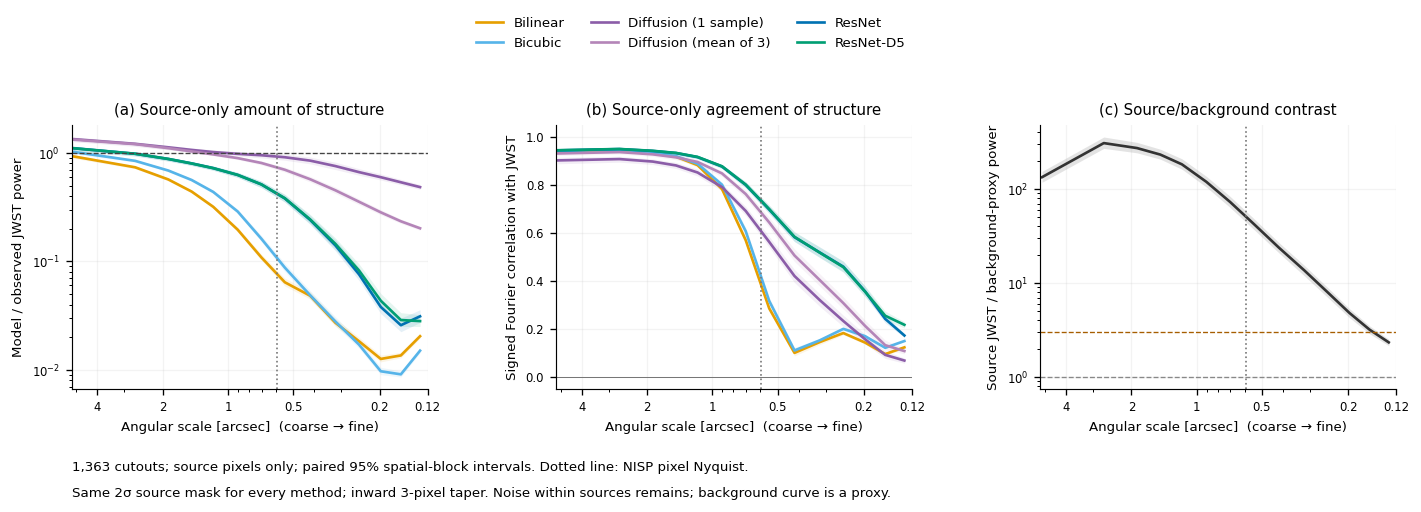

Exported: fig06_source_spatial_structure_v01.pdf, fig06_source_spatial_structure_v01.svg, fig06_source_spatial_structure_v01.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_source_spatial_structure_v01.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_source_spatial_structure_v01.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_source_spatial_structure_v01.png')]

In [2]:
def scale_axis(ax):
    ax.set_xscale('log')
    ax.set_xlim(scale[0]*1.02,scale[-1]/1.02)
    ticks=[4,2,1,.5,.2,.12]
    ax.set_xticks(ticks,[str(t) for t in ticks])
    ax.set_xlabel('Angular scale [arcsec]  (coarse → fine)')
    ax.axvline(native_nyquist_scale,color='#777777',ls=':',lw=1)
    ax.grid(alpha=.15)

fig,axes=plt.subplots(1,3,figsize=(12,4.0))
for name in names:
    for ax,key,exponent in [(axes[0],'log_power_ratio',True),(axes[1],'correlation',False)]:
        rec=main['methods'][name][key]
        y=np.array(rec['mean'][:nrings]);ci=np.array(rec['ci95'][:nrings])
        if exponent:y=10**y;ci=10**ci
        ax.plot(scale,y,color=colors[name],label=labels[name],lw=1.6)
        ax.fill_between(scale,ci[:,0],ci[:,1],color=colors[name],alpha=.10,lw=0)
axes[0].set_yscale('log');axes[0].axhline(1,color='#444444',ls='--',lw=.8)
axes[0].set_ylabel('Model / observed JWST power')
axes[0].set_title('(a) Source-only amount of structure')
axes[1].set_ylim(-.05,1.05);axes[1].axhline(0,color='#777777',lw=.6)
axes[1].set_ylabel('Signed Fourier correlation with JWST')
axes[1].set_title('(b) Source-only agreement of structure')
noise=result['reference_background_log_ratio']
y=10**np.array(noise['mean'][:nrings]);ci=10**np.array(noise['ci95'][:nrings])
axes[2].plot(scale,y,color='#333333',lw=1.6)
axes[2].fill_between(scale,ci[:,0],ci[:,1],color='#777777',alpha=.2,lw=0)
axes[2].axhline(1,color='#888888',ls='--',lw=.8)
axes[2].axhline(3,color='#A65E00',ls='--',lw=.8)
axes[2].set_yscale('log');axes[2].set_ylabel('Source JWST / background-proxy power')
axes[2].set_title('(c) Source/background contrast')
for ax in axes:scale_axis(ax)
handles,legend_labels=axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc='upper center',ncol=3,frameon=False,bbox_to_anchor=(.5,1.05),fontsize=8)
fig.subplots_adjust(left=.07,right=.99,top=.80,bottom=.25,wspace=.36)
fig.text(.07,.08,f"{main['objects']:,} cutouts; source pixels only; paired 95% spatial-block intervals. Dotted line: NISP pixel Nyquist.",fontsize=8)
fig.text(.07,.025,'Same 2σ source mask for every method; inward 3-pixel taper. Noise within sources remains; background curve is a proxy.',fontsize=8)
plt.show()
export(fig,f'fig06_source_spatial_structure_{VERSION}','06c_source_spatial_structure.ipynb',
       [path],dict(primary_objects=main['objects'],window=result['main_window'],
                   power=result['power'],correlation=result['correlation'],pixel_scale_arcsec=pixel_scale),
       status='Local exploratory power and phase-correlation comparison; noisy observed reference')


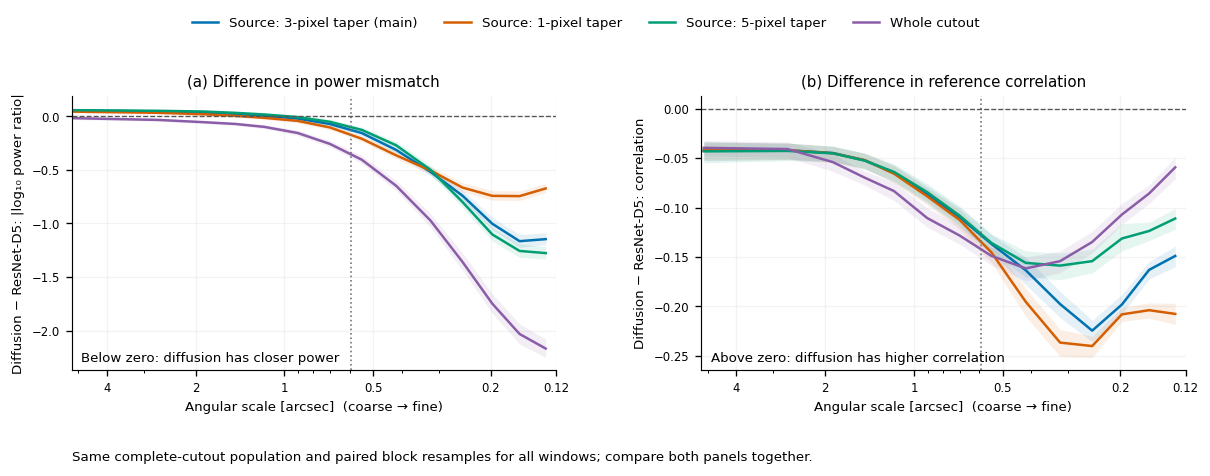

Exported: fig06_source_window_checks_v01.pdf, fig06_source_window_checks_v01.svg, fig06_source_window_checks_v01.png


,band,objects,method,power_ratio,correlation
0,large_15_30px,1343,Bilinear,0.352711,0.887356
1,large_15_30px,1343,Bicubic,0.466430,0.894016
2,large_15_30px,1343,Diffusion (1 sample),1.024952,0.863955
3,large_15_30px,1343,Diffusion (mean of 3),0.980850,0.903678
4,large_15_30px,1343,ResNet,0.743538,0.923035
5,large_15_30px,1343,ResNet-D5,0.743950,0.923891
6,intermediate_6_15px,1322,Bilinear,0.086860,0.450446
7,intermediate_6_15px,1322,Bicubic,0.122655,0.485700
8,intermediate_6_15px,1322,Diffusion (1 sample),0.901703,0.613430
9,intermediate_6_15px,1322,Diffusion (mean of 3),0.718024,0.694991


In [3]:
fig,axes=plt.subplots(1,2,figsize=(10.2,4.0))
case_labels={'source3':'Source: 3-pixel taper (main)','source1':'Source: 1-pixel taper','source5':'Source: 5-pixel taper','whole':'Whole cutout'}
case_colors={'source3':'#0072B2','source1':'#D55E00','source5':'#009E73','whole':'#8B5DA8'}
for case,label in case_labels.items():
    paired=result['paired_diffusion_vs_resnet']['direct5'][case]
    for ax,key in zip(axes,['absolute_log_power_error_difference','correlation_difference']):
        rec=paired[key];y=np.array(rec['mean'][:nrings]);ci=np.array(rec['ci95'][:nrings])
        ax.plot(scale,y,color=case_colors[case],label=label,lw=1.5)
        ax.fill_between(scale,ci[:,0],ci[:,1],color=case_colors[case],alpha=.1,lw=0)
axes[0].set_title('(a) Difference in power mismatch')
axes[0].set_ylabel('Diffusion − ResNet-D5: |log₁₀ power ratio|')
axes[1].set_title('(b) Difference in reference correlation')
axes[1].set_ylabel('Diffusion − ResNet-D5: correlation')
for ax in axes:scale_axis(ax);ax.axhline(0,color='#555555',lw=.8,ls='--')
axes[0].text(.02,.03,'Below zero: diffusion has closer power',transform=axes[0].transAxes,fontsize=8)
axes[1].text(.02,.03,'Above zero: diffusion has higher correlation',transform=axes[1].transAxes,fontsize=8)
handles,legend_labels=axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc='upper center',ncol=4,frameon=False,bbox_to_anchor=(.5,1.01),fontsize=8)
fig.subplots_adjust(left=.08,right=.99,top=.82,bottom=.25,wspace=.3)
fig.text(.08,.06,'Same complete-cutout population and paired block resamples for all windows; compare both panels together.',fontsize=8)
plt.show()
export(fig,f'fig06_source_window_checks_{VERSION}','06c_source_spatial_structure.ipynb',
       [path],dict(primary_objects=main['objects'],cases=list(case_labels),baseline='direct5'),
       status='Paired diffusion versus ResNet-D5 window-sensitivity diagnostic')

# Optional reference-contrast subsets, separate from the main all-object curves.
rows=[]
for band,summary in result['contrast_band_summaries'].items():
    for name,metrics in summary['methods'].items():
        rows.append(dict(band=band,objects=summary['objects'],method=labels[name],
            power_ratio=10**metrics['log_power_ratio']['mean'],correlation=metrics['correlation']['mean']))
display(pd.DataFrame(rows))


In [4]:
# Main-population comparison: identical objects for source and whole cutout.
rows=[]
for case in ['whole','source3','source1','source5']:
    for band_index,band in enumerate(result['bands_cycles_per_pixel']):
        for name in ['diffusion','diffusion_mean3','legacy','direct5']:
            metrics=result['summaries'][case]['methods'][name]
            rows.append(dict(window=case,band=band,method=labels[name],
                power_ratio=10**metrics['log_power_ratio']['mean'][nrings+band_index],
                correlation=metrics['correlation']['mean'][nrings+band_index]))
display(pd.DataFrame(rows))


,window,band,method,power_ratio,correlation
0,whole,large_15_30px,Diffusion (1 sample),0.943868,0.796412
1,whole,large_15_30px,Diffusion (mean of 3),0.825574,0.844651
2,whole,large_15_30px,ResNet,0.580106,0.876657
3,whole,large_15_30px,ResNet-D5,0.579893,0.877265
4,whole,intermediate_6_15px,Diffusion (1 sample),0.904026,0.500662
...,...,...,...,...,...
59,source5,fine_3_6px,ResNet-D5,0.090801,0.385063
60,source5,finest_2_3px,Diffusion (1 sample),0.507371,0.069065
61,source5,finest_2_3px,Diffusion (mean of 3),0.215683,0.100896
62,source5,finest_2_3px,ResNet,0.021025,0.162387


## Interpretation

Closer power to JWST indicates a more similar amount of spatial variation,
while higher signed correlation indicates better alignment with the reference.
Neither alone establishes faithful recovery of fine galaxy structure. Source
masking removes outside-source contributions exactly, but does not remove
reference noise within galaxies, band/PSF differences, or mode coupling due to
the source-window geometry. Compare the source-boundary taper checks before
interpreting small-scale power. The diffusion draw is a fixed seed, with no
best-sample selection. All neighbours selected by the frozen mask are retained.
